# MNet-LSTM + paraphrases (Ours)

Standalone notebook for the proposed lightweight plant leaf disease VQA model:
- **Image encoder:** MobileNetV3-Large (`mobilenetv3_large_100`, final stage fine-tuned) -> 960-d
- **Question encoder:** Word embedding (300-d) + 2-layer Bi-LSTM -> 512-d
- **Fusion & head:** Raw concatenation `[v ; q]` (1472-d) -> MLP -> 15 answers

Run from the repository root (`lightweight-plant-disease-vqa/`).

## 1. Setup

In [1]:
import os
import json
import re
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import timm
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import f1_score
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

try:
    from IPython.display import display
except ImportError:
    display = print

CHECKPOINT   = os.environ.get('RIMA_CHECKPOINT',   'checkpoints/mnet_lstm_finetuned_concat_raw_paraphrases/seed42/model_best.pth')
DATA_DIR     = os.environ.get('RIMA_DATA_DIR',     '')  # Optional: path to RiMa VQA JSON directory
IMAGE_ROOT   = os.environ.get('RIMA_IMAGE_ROOT',   DATA_DIR)
SAMPLE_IMAGE = os.environ.get('RIMA_SAMPLE_IMAGE', 'examples/sample_rice_brown_spot.jpg')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE} | PyTorch: {torch.__version__} | timm: {timm.__version__}')

Device: cuda | PyTorch: 2.11.0+cu128 | timm: 1.0.27


## 2. Architecture & Checkpoint Loading

In [2]:
TOKEN_RE = re.compile(r"[a-z0-9]+(?:'[a-z]+)?|[^\sa-z0-9]")


class MNetLSTM(nn.Module):
    def __init__(self, word_to_idx, num_classes=15, embed_dim=300, hidden_dim=512, lstm_layers=2,
                 max_len=32, dropout=0.2, pretrained=True):
        super().__init__()
        self.word_to_idx, self.max_len = word_to_idx, max_len
        # Image encoder: MobileNetV3-Large, frozen except the last two blocks
        self.vision = nn.Module()
        self.vision.cnn = timm.create_model('mobilenetv3_large_100', pretrained=pretrained,
                                           features_only=True, out_indices=(4,))
        for p in self.vision.cnn.parameters():
            p.requires_grad = False
        for block in list(self.vision.cnn.blocks.children())[-2:]:
            for p in block.parameters():
                p.requires_grad = True
        # Question encoder: word embedding + 2-layer Bi-LSTM
        self.embedding = nn.Embedding(len(word_to_idx), embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim // 2, num_layers=lstm_layers, batch_first=True,
                            bidirectional=True, dropout=dropout)
        # Fusion [v ; q] (960 + 512) -> MLP head
        self.classifier = nn.Sequential(
            nn.Linear(960 + hidden_dim, hidden_dim), nn.LayerNorm(hidden_dim), nn.ReLU(inplace=True),
            nn.Dropout(dropout), nn.Linear(hidden_dim, num_classes))

    def tokenize(self, questions, device):
        ids = [[self.word_to_idx.get(w, 1) for w in TOKEN_RE.findall(q.lower())][:self.max_len] or [1]
               for q in questions]
        lengths = torch.tensor([len(t) for t in ids])
        ids = torch.tensor([t + [0] * (self.max_len - len(t)) for t in ids], device=device)
        return ids, lengths

    def forward(self, images, questions):
        v = self.vision.cnn(images)[-1].mean(dim=(2, 3))                         # [B, 960]
        ids, lengths = self.tokenize(questions, images.device)
        packed = pack_padded_sequence(self.embedding(ids), lengths, batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(packed)
        q = torch.cat([h[-2], h[-1]], dim=-1)                                     # [B, 512]
        return self.classifier(torch.cat([v, q], dim=-1))                        # [B, 15]

    def train(self, mode=True):
        super().train(mode)
        if mode:                                          # frozen parts keep fixed BatchNorm statistics
            for block in [*self.vision.cnn.children(), *self.vision.cnn.blocks.children()]:
                if not any(p.requires_grad for p in block.parameters()):
                    block.eval()
        return self

In [3]:
ckpt = torch.load(CHECKPOINT, map_location='cpu', weights_only=False)
model = MNetLSTM(ckpt['word_to_idx'], num_classes=len(ckpt['vocab']), pretrained=False)
model.load_state_dict(ckpt['state_dict'], strict=True)
model = model.to(DEVICE).eval()
idx_to_ans = {int(i): a for a, i in ckpt['vocab'].items()}

n_all = sum(p.numel() for p in model.parameters()) / 1e6
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6
print(f'Checkpoint epoch {ckpt.get("epoch")} | params {n_all:.2f} M (trainable {n_train:.2f} M) | '
      f'word vocab {len(ckpt["word_to_idx"])} | answers {len(idx_to_ans)}')
print('Answers:', [idx_to_ans[i] for i in sorted(idx_to_ans)])

Checkpoint epoch 14 | params 6.47 M (trainable 5.68 M) | word vocab 59 | answers 15
Answers: ['A healthy maize leaf.', 'A healthy rice leaf.', 'Bacterial leaf blight on a rice leaf.', 'Bacterial leaf streak on a rice leaf.', 'Blast on a rice leaf.', 'Brown spot on a rice leaf.', 'Gray leaf spot on a maize leaf.', 'Maize lethal necrosis on a maize leaf.', 'Maize streak virus disease on a maize leaf.', 'No.', 'Northern corn leaf spot on a maize leaf.', 'Northern leaf blight on a maize leaf.', 'Rice tungro disease on a rice leaf.', 'Sheath blight on a rice leaf.', 'Yes.']


## 3. Single-Image Inference

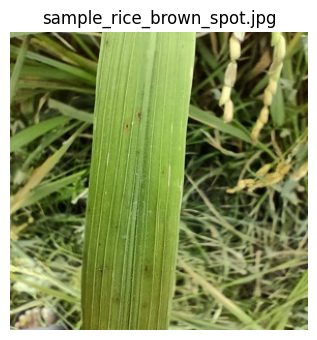

,question,answer,confidence
0,What disease does this leaf have?,Brown spot on a rice leaf.,100.00
1,Is there a lesion on this leaf?,Yes.,99.94


In [4]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])


@torch.no_grad()
def ask_leaf(image_path: str, questions):
    # Read RGB without EXIF orientation transpose (matches RiMa protocol)
    img = Image.open(image_path).convert('RGB')
    x = eval_transform(img).unsqueeze(0).to(DEVICE)
    out = []
    for q in questions:
        probs = model(x, [q]).float().softmax(dim=-1)[0]
        idx = int(probs.argmax().item())
        out.append({'question': q, 'answer': idx_to_ans[idx], 'confidence': round(100.0 * float(probs[idx]), 2)})
    return pd.DataFrame(out)


demo_path = SAMPLE_IMAGE or (str(Path(IMAGE_ROOT) / 'images/001952.jpg') if IMAGE_ROOT else '')
if demo_path and Path(demo_path).is_file():
    leaf_img = Image.open(demo_path).convert('RGB')
    plt.figure(figsize=(3.5, 3.5))
    plt.imshow(leaf_img)
    plt.axis('off')
    plt.title(Path(demo_path).name)
    plt.tight_layout()
    plt.show()
    display(ask_leaf(demo_path, ['What disease does this leaf have?', 'Is there a lesion on this leaf?']))
else:
    print('Pass any leaf image path to ask_leaf(path, questions) or set RIMA_SAMPLE_IMAGE.')

## 4. Standard RiMa Test-Set Evaluation (Optional)

In [5]:
class RiMaStandardTestDataset(Dataset):
    def __init__(self, json_path: str, image_root: str, vocab: dict, transform):
        raw = json.loads(Path(json_path).read_text(encoding='utf-8'))
        self.items = [it for it in raw if it.get('category') in ('perception', 'presence')]
        self.image_root = Path(image_root)
        self.vocab = vocab
        self.transform = transform

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        it = self.items[idx]
        img = self.transform(Image.open(self.image_root / it['image_path']).convert('RGB'))
        return {
            'image': img,
            'question': it['question'],
            'answer': self.vocab[it['answer']],
            'category': it['category'],
            'image_id': int(it['image_id']),
        }


def compute_metrics(preds, tgts, cats, imgs, idx_to_ans):
    presence_ids = sorted(i for i, a in idx_to_ans.items() if a in ('Yes.', 'No.'))
    perception_ids = sorted(i for i in idx_to_ans if i not in set(presence_ids))
    per_i = [i for i, c in enumerate(cats) if c == 'perception']
    pre_i = [i for i, c in enumerate(cats) if c == 'presence']
    acc = lambda y, p: 100.0 * sum(a == b for a, b in zip(y, p)) / len(y)
    mf1 = lambda y, p, lbl: 100.0 * float(f1_score(y, p, labels=lbl, average='macro', zero_division=0))
    per_map = {imgs[i]: idx_to_ans[preds[i]] for i in per_i}
    pre_map = {imgs[i]: idx_to_ans[preds[i]] for i in pre_i}
    common = sorted(set(per_map) & set(pre_map))
    cons = 100.0 * sum(per_map[k].lower().startswith('a healthy') == (pre_map[k] == 'No.') for k in common) / len(common)
    return {
        'accuracy_top1': round(acc(tgts, preds), 2),
        'macro_f1': round(mf1(tgts, preds, sorted(idx_to_ans)), 2),
        'perception_macro_f1': round(mf1([tgts[i] for i in per_i], [preds[i] for i in per_i], perception_ids), 2),
        'presence_f1': round(mf1([tgts[i] for i in pre_i], [preds[i] for i in pre_i], presence_ids), 2),
        'consistency': round(cons, 2),
    }


test_json = Path(DATA_DIR) / 'test.json' if DATA_DIR else None
if test_json and test_json.is_file() and IMAGE_ROOT:
    ds = RiMaStandardTestDataset(str(test_json), IMAGE_ROOT, ckpt['vocab'], eval_transform)
    loader = DataLoader(ds, batch_size=128, shuffle=False, num_workers=0)
    preds, tgts, cats, imgs = [], [], [], []
    with torch.no_grad():
        for b in loader:
            with torch.autocast('cuda', dtype=torch.bfloat16, enabled=DEVICE.type == 'cuda'):
                preds += model(b['image'].to(DEVICE), b['question']).argmax(1).tolist()
            tgts += b['answer'].tolist()
            cats += b['category']
            imgs += b['image_id'].tolist()
    print(pd.Series(compute_metrics(preds, tgts, cats, imgs, idx_to_ans)))
else:
    print('Set RIMA_DATA_DIR and RIMA_IMAGE_ROOT to run evaluation on local RiMa test.json.')

Set RIMA_DATA_DIR and RIMA_IMAGE_ROOT to run evaluation on local RiMa test.json.


## 5. Paper Summary & Training History (from CSVs)

In [6]:
summary_df = pd.read_csv('results/tables/summary.csv')
print('Proposed model row in results/tables/summary.csv:')
display(summary_df[summary_df['model'] == 'mnet_lstm_finetuned_concat_raw_paraphrases'])

seed_rows = []
for seed in ('seed7', 'seed42', 'seed123'):
    hist = pd.read_csv(f'results/combined/mnet_lstm_finetuned_concat_raw_paraphrases/{seed}/training_history.csv')
    best = hist.loc[hist['val_macro_f1'].idxmax()]
    seed_rows.append({
        'seed': seed,
        'best_epoch': int(best['epoch']),
        'val_macro_f1': round(float(best['val_macro_f1']), 2),
        'val_consistency': round(float(best['val_consistency']), 2),
        'train_loss': round(float(best['train_loss']), 4),
    })
print('Proposed model best validation epochs from training_history.csv:')
display(pd.DataFrame(seed_rows))

Proposed model row in results/tables/summary.csv:


,group,model,paper_label,runs,acc,macro_f1,perception_f1,presence_f1,consistency,para_acc,para_macro_f1,trainable_M,ms_per_sample,vram_mb
25,combined,mnet_lstm_finetuned_concat_raw_paraphrases,MNet-LSTM + paraphrases (Ours),3,95.69 ± 0.15,95.56 ± 0.17,95.16 ± 0.19,98.15 ± 0.06,98.91 ± 0.19,95.68 ± 0.15,95.54 ± 0.18,5.680 ± 0.000,2.08 ± 0.03,315 ± 5


Proposed model best validation epochs from training_history.csv:


,seed,best_epoch,val_macro_f1,val_consistency,train_loss
0,seed7,15,96.08,98.95,0.0330
1,seed42,14,96.58,99.48,0.0348
2,seed123,11,96.53,99.28,0.0448
